# M115 Lab 1: Phishing URL Detection
### EDA, Parameterized Logistic Regression & SHAP Explainability

---

## 🏛️ ENSIASD Taroudant — Ibn Zohr University

**Master in Intelligent Systems and Cyber Defense**  
**Module:** M115 – AI & Intelligent Systems  
**Instructor:** Prof. Sara EL-ATEIF  
**Academic Year:** 2026–2027

---

## 🧭 Lab Overview

This notebook documents the work carried out for **Lab 1: Phishing URL Detection**, using the [PhiUSIIL Phishing URL Dataset](https://www.kaggle.com/datasets/kaggleprollc/phishing-url-websites-dataset-phiusiil/data).

The dataset contains **235,795 URLs and 56 lexical, network, and HTML-related features** (Prasad & Chandra, *Computers & Security*, 2024).

The objective is to explore the dataset, prepare the data without leakage, implement and compare parameterized Logistic Regression models, and interpret their predictions using SHAP.
### 📋 Table of Contents

1. **Importing Packages & Loading Data**

2. **Part 1: Security-Oriented Exploratory Data Analysis (EDA)**
   - 2.1 Data Quality Inspection & SOC Target Alignment (Exercise 1)
   - 2.2 Class Balance, Numerical Distributions & Binary Security Indicators (Exercise 2)
   - 2.3 Identifier Cleanup & Feature–Target Correlations (Exercise 3)
   - Part 1 Reflection Questions

3. **Part 2: Zero-Data-Leakage Preprocessing & Standardization**
   - 3.1 Stratified 75/25 Split & Training-Only StandardScaler (Exercise 4)
   - Part 2 Reflection Questions

4. **Part 3: Parameterized Logistic Regression & Interpretability**
   - 4.1 Comparing Five Logistic Regression Configurations (Exercise 5)
   - 4.2 L1 Regularization Path & Feature Selection (Exercise 6)
   - 4.3 Interpreting Coefficients (\(w_j\)) and Odds Ratios (\(e^{w_j}\)) (Exercise 7)
   - Part 3 Reflection Questions

5. **Part 4: Explainable AI (SHAP) & SOC Threshold Analysis**
   - 5.1 Global Explanations with `shap.LinearExplainer` (Exercise 8)
   - 5.2 Local SOC Alert Triage: TP, TN, and FP Waterfall Plots (Exercise 9)
   - 5.3 Operational Decision Threshold Tuning (\(\tau \in \{0.20, 0.50, 0.85\}\)) (Exercise 10)
   - Part 4 Reflection Questions

6. **Conclusion & SOC Engineering Synthesis**

---

**Author:** SARRAD Youssef  
**Program:** Master in Intelligent Systems and Cyber Defense  
**Institution:** ENSIASD Taroudant — Ibn Zohr University


# Part 1: Security-Oriented Exploratory Data Analysis (EDA)

This first step is essential for verifying data quality, understanding malicious URL structures, avoiding labeling traps, and removing textual columns that could cause overfitting through memorization.

## Exercice 1: Importing the data and Initial processing

In [64]:
import os

print("Available Kaggle inputs:")

for root, dirs, files in os.walk("/kaggle/input"):
    print("Folder:", root)
    for file in files:
        print("File:", file)

Available Kaggle inputs:
Folder: /kaggle/input
Folder: /kaggle/input/datasets
Folder: /kaggle/input/datasets/youssefsarrad
Folder: /kaggle/input/datasets/youssefsarrad/dataset
File: PhiUSIIL_Phishing_URL_Dataset.csv
Folder: /kaggle/input/datasets/kaggleprollc
Folder: /kaggle/input/datasets/kaggleprollc/phishing-url-websites-dataset-phiusiil
File: PhiUSIIL_Phishing_URL_Dataset.csv


## 1.1 Import Libraries and Load Dataset

In this step, we import the required Python libraries for data manipulation, visualization, preprocessing, model training, and performance evaluation. We then load the PhiUSIIL Phishing URL Dataset into a Pandas DataFrame and display the first five rows to inspect its initial structure.

In [122]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score
)

SEED = 42

df = pd.read_csv(
    "/kaggle/input/datasets/youssefsarrad/dataset/PhiUSIIL_Phishing_URL_Dataset.csv"
)
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


## 1.2 Data Quality Assessment

In this step, I inspect the dataset structure, check for missing values and duplicate records, and analyze the statistical distribution of numerical features to assess data quality.

In [66]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  object 
 1   URL                         235795 non-null  object 
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  object 
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  object 
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation

In [67]:
df.isna().sum()

FILENAME                      0
URL                           0
URLLength                     0
Domain                        0
DomainLength                  0
IsDomainIP                    0
TLD                           0
URLSimilarityIndex            0
CharContinuationRate          0
TLDLegitimateProb             0
URLCharProb                   0
TLDLength                     0
NoOfSubDomain                 0
HasObfuscation                0
NoOfObfuscatedChar            0
ObfuscationRatio              0
NoOfLettersInURL              0
LetterRatioInURL              0
NoOfDegitsInURL               0
DegitRatioInURL               0
NoOfEqualsInURL               0
NoOfQMarkInURL                0
NoOfAmpersandInURL            0
NoOfOtherSpecialCharsInURL    0
SpacialCharRatioInURL         0
IsHTTPS                       0
LineOfCode                    0
LargestLineLength             0
HasTitle                      0
Title                         0
DomainTitleMatchScore         0
URLTitle

In [68]:
df.duplicated().sum()

np.int64(0)

In [69]:
df.describe()

,URLLength,DomainLength,IsDomainIP,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
count,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,...,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000
mean,34.573095,21.470396,0.002706,78.430778,0.845508,0.260423,0.055747,2.764456,1.164758,0.002057,...,0.237007,0.023474,0.486775,26.075689,6.333111,10.522305,65.071113,2.377629,49.262516,0.571895
std,41.314153,9.150793,0.051946,28.976055,0.216632,0.251628,0.010587,0.599739,0.600969,0.045306,...,0.425247,0.151403,0.499826,79.411815,74.866296,22.312192,176.687539,17.641097,161.027430,0.494805
min,13.000000,4.000000,0.000000,0.155574,0.000000,0.000000,0.001083,2.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,23.000000,16.000000,0.000000,57.024793,0.680000,0.005977,0.050747,2.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,27.000000,20.000000,0.000000,100.000000,1.000000,0.079963,0.057970,3.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,8.000000,2.000000,6.000000,12.000000,0.000000,10.000000,1.000000
75%,34.000000,24.000000,0.000000,100.000000,1.000000,0.522907,0.062875,3.000000,1.000000,0.000000,...,0.000000,0.000000,1.000000,29.000000,8.000000,15.000000,88.000000,1.000000,57.000000,1.000000
max,6097.000000,110.000000,1.000000,100.000000,1.000000,0.522907,0.090824,13.000000,10.000000,1.000000,...,1.000000,1.000000,1.000000,8956.000000,35820.000000,6957.000000,27397.000000,4887.000000,27516.000000,1.000000


### 1.3 Investigation of Missing Values

I identify the rows containing missing values and inspect them to understand which features are affected and determine whether any data-cleaning steps are necessary.

In [70]:
missing_rows = df[df.isna().any(axis=1)]

print("Number of affected rows:", len(missing_rows))
display(missing_rows)

Number of affected rows: 0


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label


### 1.4 Investigation of Extreme Values

I examine selected numerical features, particularly URL length and lines of code, to identify unusually large values that could indicate outliers or suspicious URL characteristics.

In [71]:
df[['URLLength', 'LineOfCode', 'NoOfSelfRef']].describe()

,URLLength,LineOfCode,NoOfSelfRef
count,235795.000000,235795.000000,235795.000000
mean,34.573095,1141.900443,65.071113
std,41.314153,3419.950513,176.687539
min,13.000000,2.000000,0.000000
25%,23.000000,18.000000,0.000000
50%,27.000000,429.000000,12.000000
75%,34.000000,1277.000000,88.000000
max,6097.000000,442666.000000,27397.000000


In [72]:
df.nlargest(5, 'LineOfCode')[['URLLength', 'LineOfCode', 'NoOfSelfRef']]

,URLLength,LineOfCode,NoOfSelfRef
8376,27,442666,52
82201,21,440155,225
60856,24,422798,198
222733,24,418650,485
1046,21,402747,197


### 1.5 Target Variable Definition and Class Distribution

I create the `IsPhishing` target variable by reversing the original `label` values, then examine the class distribution to understand the proportion of phishing and legitimate URLs.

In [73]:
df['IsPhishing'] = 1 - df['label']
df['IsPhishing'].value_counts(normalize=True)

IsPhishing
0    0.571895
1    0.428105
Name: proportion, dtype: float64

### Exercise 1 — Initial Dataset Assessment

The dataset contains **235,795 records and 56 columns**, representing URL-related characteristics used for phishing detection.

**Data quality:**
- No missing values were detected.
- No exact duplicate rows were found.
- The dataset contains numerical and categorical features.

**Extreme values:**

Some numerical features contain unusually large maximum values:
- `URLLength`: 6,097
- `LineOfCode`: 442,666
- `NoOfSelfRef`: 27,397

These values may represent outliers and should be investigated during the analysis rather than removed automatically.

**Target variable:**

The original `label` column was transformed into `IsPhishing`, where:
- `0` represents legitimate URLs (57.19%).
- `1` represents phishing URLs (42.81%).

**Initial conclusion:**

The dataset is suitable for further exploratory analysis. Its class distribution is relatively balanced, although legitimate URLs are slightly more frequent than phishing URLs.

## exercise 2: Data Preprocessing and Feature Preparation

This step focuses on preparing the dataset for machine learning by handling data quality issues, selecting relevant features, defining the target variable, and preparing the data for model training and evaluation.

## 2.1 Target Class Distribution

I visualize the distribution of legitimate and phishing URLs to identify class imbalance and understand the representation of each class in the dataset.

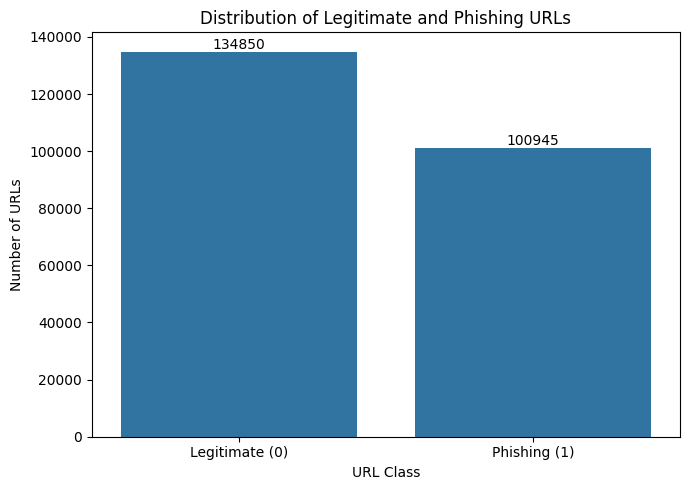

In [74]:
plt.figure(figsize=(7, 5))

ax = sb.countplot(data=df, x='IsPhishing')

plt.title('Distribution of Legitimate and Phishing URLs')
plt.xlabel('URL Class')
plt.ylabel('Number of URLs')

plt.xticks(
    [0, 1],
    ['Legitimate (0)', 'Phishing (1)']
)

# Display values above bars
ax.bar_label(ax.containers[0])

plt.tight_layout()
plt.show()

## 2.2 Feature Distribution Analysis

In this step I compare the distributions of selected numerical features between legitimate and phishing URLs using KDE plots to identify differences in their statistical patterns and assess their potential usefulness for classification.

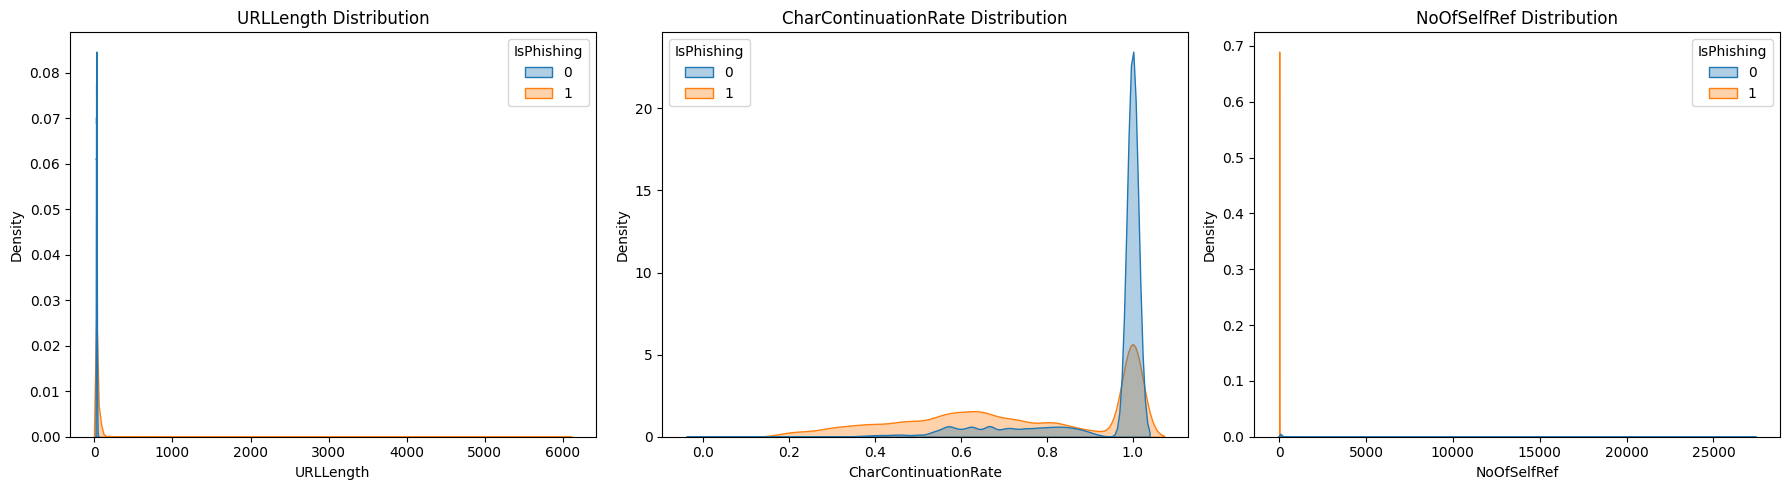

In [75]:
features = [
    'URLLength',
    'CharContinuationRate',
    'NoOfSelfRef'
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, feature in enumerate(features):
    sb.kdeplot(
        data=df,
        x=feature,
        hue='IsPhishing',
        fill=True,
        common_norm=False,
        alpha=0.35,
        ax=axes[i]
    )

    axes[i].set_title(f'{feature} Distribution')
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Density')

plt.tight_layout()
plt.show()

In [76]:
binary_features = [
    'IsHTTPS',
    'HasPasswordField',
    'HasCopyrightInfo',
    'HasSocialNet'
]

# Calculate the mean of binary features for each class
prevalence = df.groupby('IsPhishing')[binary_features].mean() * 100

prevalence.index = ['Legitimate', 'Phishing']

display(prevalence.round(2))

,IsHTTPS,HasPasswordField,HasCopyrightInfo,HasSocialNet
Legitimate,100.00,13.85,80.82,79.46
Phishing,49.22,5.39,5.73,0.51


## 2.3 Binary Security Indicators Analysis

I compare the prevalence of selected binary security indicators between legitimate and phishing URLs to identify patterns and determine whether these indicators can help distinguish between the two classes.

<Figure size 1000x600 with 0 Axes>

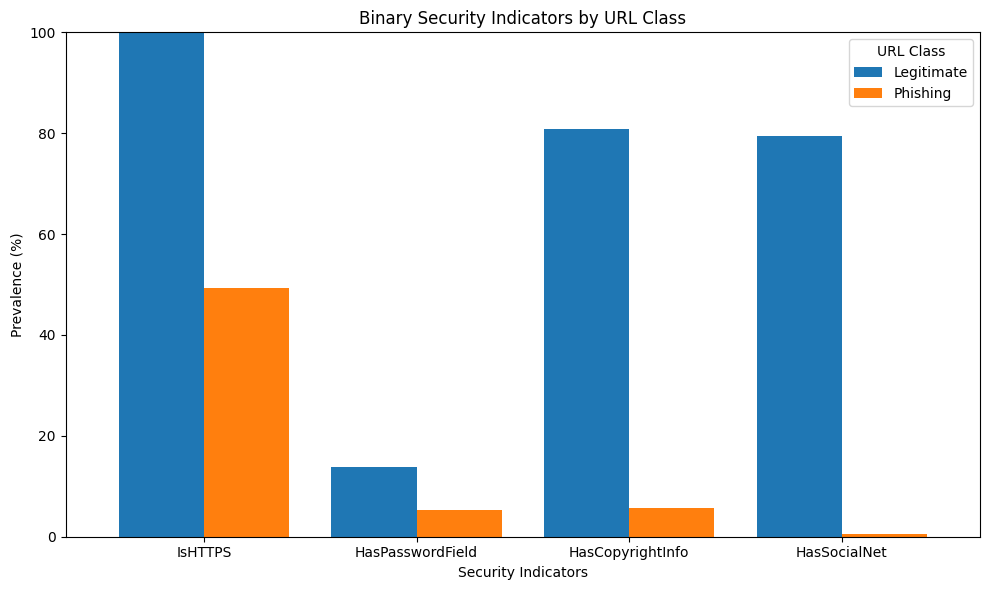

In [77]:
plt.figure(figsize=(10, 6))

prevalence.T.plot(
    kind='bar',
    figsize=(10, 6),
    width=0.8
)

plt.title('Binary Security Indicators by URL Class')
plt.xlabel('Security Indicators')
plt.ylabel('Prevalence (%)')
plt.xticks(rotation=0)
plt.legend(title='URL Class')
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

## 2.4 Feature Selection and Removal of Textual Columns

here i remove unnecessary textual and identifier columns using the code in below to reduce the risk of overfitting caused by memorization and retain the numerical features required for machine learning.

In [78]:
# Columns to remove
columns_to_drop = [
    'FILENAME',
    'URL',
    'Domain',
    'TLD',
    'Title',
    'label',
    'URLSimilarityIndex'
]

# Create a cleaned dataset
df_clean = df.drop(columns=columns_to_drop)


print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

display(df_clean.head())

Original shape: (235795, 57)
Cleaned shape: (235795, 50)


,URLLength,DomainLength,IsDomainIP,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,IsPhishing
0,31,24,0,1.000000,0.522907,0.061933,3,1,0,0,...,0,0,1,34,20,28,119,0,124,0
1,23,16,0,0.666667,0.032650,0.050207,2,1,0,0,...,0,0,1,50,9,8,39,0,217,0
2,29,22,0,0.866667,0.028555,0.064129,2,2,0,0,...,0,0,1,10,2,7,42,2,5,0
3,26,19,0,1.000000,0.522907,0.057606,3,1,0,0,...,1,1,1,3,27,15,22,1,31,0
4,33,26,0,1.000000,0.079963,0.059441,3,1,0,0,...,1,0,1,244,15,34,72,1,85,0


### Exercise 2 — Interpretation of Class Balance, Distributions & Binary Indicators

**Class balance.**
The dataset holds 134,850 legitimate URLs (57.19%) and 100,945 phishing URLs (42.81%). The imbalance is mild, so accuracy is not badly misleading here. In a SOC setting, though, Precision and Recall on the phishing class (positive class = 1) remain the metrics that matter. A stratified split will also be needed to preserve this ratio.

**Numerical distributions.**

| Feature | Legitimate | Phishing |
|---|---|---|
| `URLLength` (mean / median / max) | 26.2 / 26 / 57 | 45.7 / 34 / 6,097 |
| `CharContinuationRate` (mean / median) | 0.93 / 1.00 | 0.73 / 0.73 |
| `NoOfSelfRef` (mean / median) | 113.4 / 76 | 0.5 / 0 |

- **`URLLength`:** Legitimate URLs are short and tightly concentrated (std ≈ 4.8). Phishing URLs are longer on average and much more variable (std ≈ 61), with a long right tail up to 6,097 characters. Attackers pad URLs with random strings, subdomains, or encoded parameters to hide the real destination. Very long URLs therefore carry signal and should not be treated as noise to be removed.
- **`CharContinuationRate`:** Legitimate URLs are almost always close to 1.0, meaning clean, natural character sequences. Phishing URLs are shifted to lower values and spread widely. This is consistent with randomly generated or obfuscated strings that mix letters, digits, and symbols.
- **`NoOfSelfRef`:** This is the strongest separator of the three. Over 75% of phishing pages have zero internal links, whereas legitimate sites have a median of 76. Phishing pages are typically thin clones of a single login page, while real sites have full navigation structures. The feature is extremely skewed (max 27,397), so a log scale or clipping is needed to visualize it, and a transformation will help the linear model later.

**Binary security indicators (prevalence %).**

| Indicator | Legitimate | Phishing |
|---|---|---|
| `IsHTTPS` | 100.0% | 49.2% |
| `HasPasswordField` | 13.8% | 5.4% |
| `HasCopyrightInfo` | 80.8% | 5.7% |
| `HasSocialNet` | 79.5% | 0.5% |

- **`HasCopyrightInfo` and `HasSocialNet`** are the most discriminating indicators. Legitimate sites invest in complete, branded pages, while phishing pages usually omit such content.
- **`IsHTTPS`** is present on 100% of legitimate URLs but also on nearly half of phishing URLs. Encryption therefore does not prove legitimacy, and a rule like "HTTPS ⇒ safe" would miss about 49% of attacks. The 100% figure for legitimate sites is also unusually clean and may reflect how the dataset was collected, so `IsHTTPS` may look more powerful here than it would in real traffic.
- **`HasPasswordField`** is a counter-intuitive result: it is *more* common on legitimate sites (13.8%) than on phishing pages (5.4%). Many real websites have login pages, while many phishing pages in this dataset do not contain a visible password field. This feature is a weak standalone indicator and only becomes useful in combination with others.

**Conclusion.**
Phishing pages are characterized by longer, more irregular URLs, almost no internal linking, and missing "trust" content such as copyright notices and social-media links. No single binary feature is sufficient on its own. This supports using a multivariate model, and the strong separation in these features suggests high achievable performance, which we should still validate carefully for leakage and over-optimism.

## Exercise 3: Identifier Cleanup & Feature–Target Correlations:

This step focuses on splitting the dataset into training and testing sets, scaling numerical features, training a Logistic Regression model, and evaluating its performance using classification metrics and confusion matrices.

## 3.1 Feature and Target Separation

I separate the dataset into input features (X) and the target variable (y). I also check their dimensions and verify the target class distribution before splitting the data.

In [79]:
X = df_clean.drop(columns=['IsPhishing'])
y = df_clean['IsPhishing']

print("Features (X):", X.shape)
print("Target (y):", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features (X): (235795, 49)
Target (y): (235795,)

Target distribution:
IsPhishing
0    134850
1    100945
Name: count, dtype: int64


In [80]:
X = df_clean.drop(columns=['IsPhishing'])
y = df_clean['IsPhishing']

print("Features (X):", X.shape)
print("Target (y):", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features (X): (235795, 49)
Target (y): (235795,)

Target distribution:
IsPhishing
0    134850
1    100945
Name: count, dtype: int64


## 3.2 Feature Correlation Analysis

I calculate and visualize the correlations between numerical features using a correlation matrix to identify strongly correlated variables and potential multicollinearity before model training.

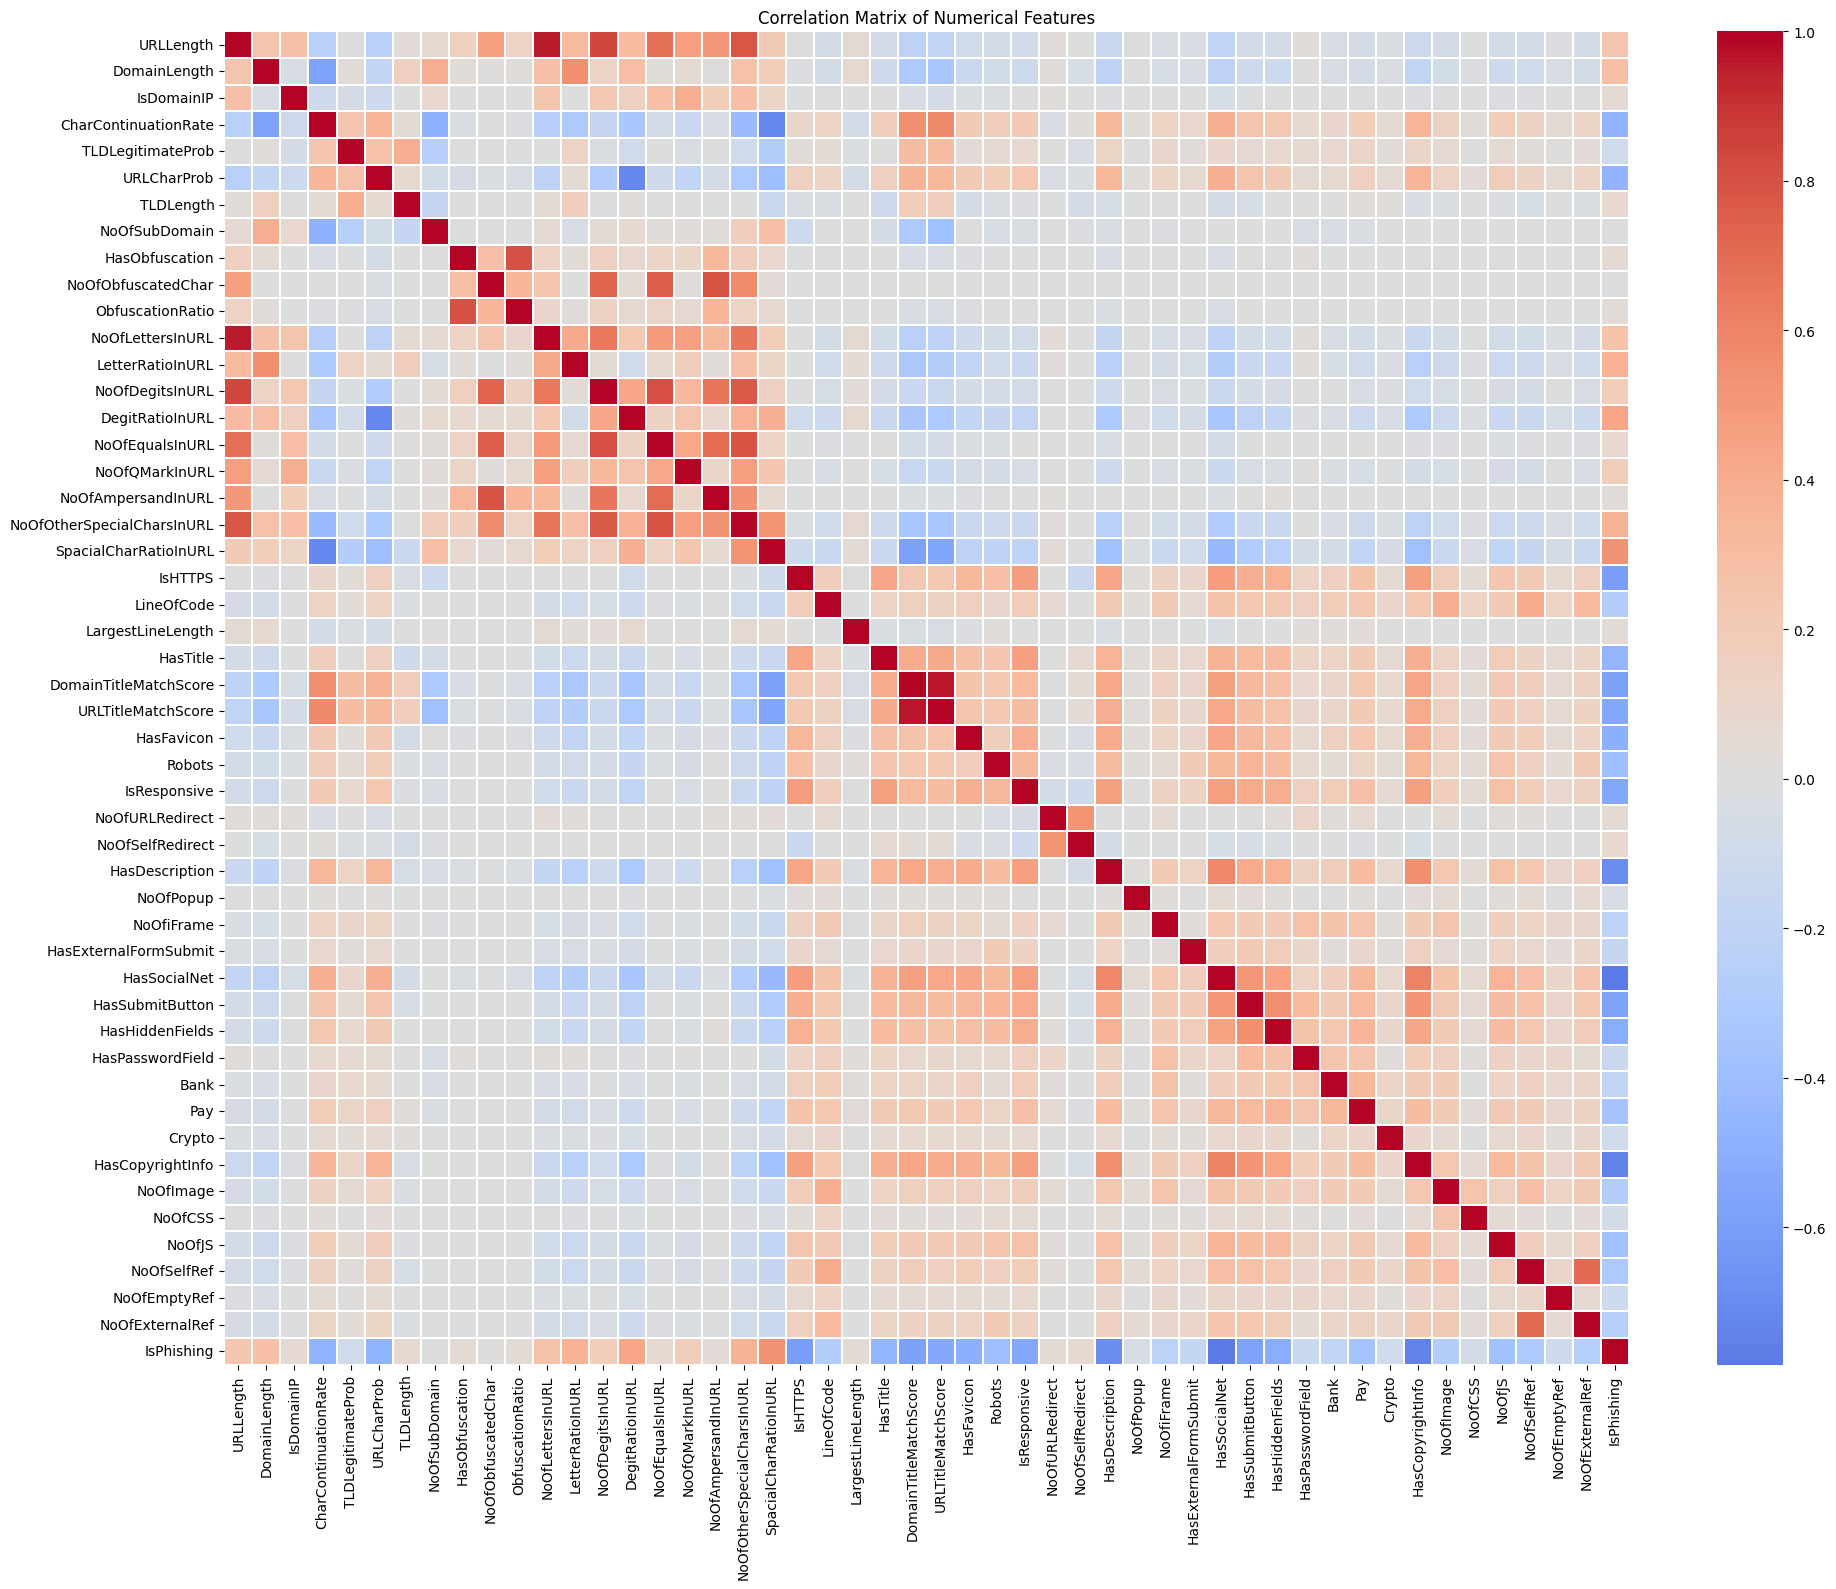

In [81]:
# Calculate correlations between numerical features
correlation_matrix = df_clean.corr(numeric_only=True)

# Visualize the correlation matrix
plt.figure(figsize=(20, 16))

sb.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    linewidths=0.1
)

plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout()
plt.show()

### 3.3 Identification of Highly Correlated Features

I identify feature pairs with an absolute correlation greater than 0.90 to detect strong relationships between variables and assess potential multicollinearity.

In [82]:
# Extract highly correlated feature pairs
corr_pairs = correlation_matrix.abs().unstack()

# Remove self-correlations and duplicate pairs
corr_pairs = corr_pairs[corr_pairs < 1]
corr_pairs = corr_pairs.sort_values(ascending=False)

# Keep unique pairs
corr_pairs = corr_pairs[::2]

# Display correlations above 0.90
high_correlations = corr_pairs[corr_pairs > 0.90]

display(high_correlations)

DomainTitleMatchScore  URLTitleMatchScore    0.961008
URLLength              NoOfLettersInURL      0.956047
dtype: float64

### 3.4 Feature Correlation with the Target Variable

I calculate the Pearson correlation between each feature and the target variable (`IsPhishing`) to identify the features most positively and negatively associated with phishing URLs.

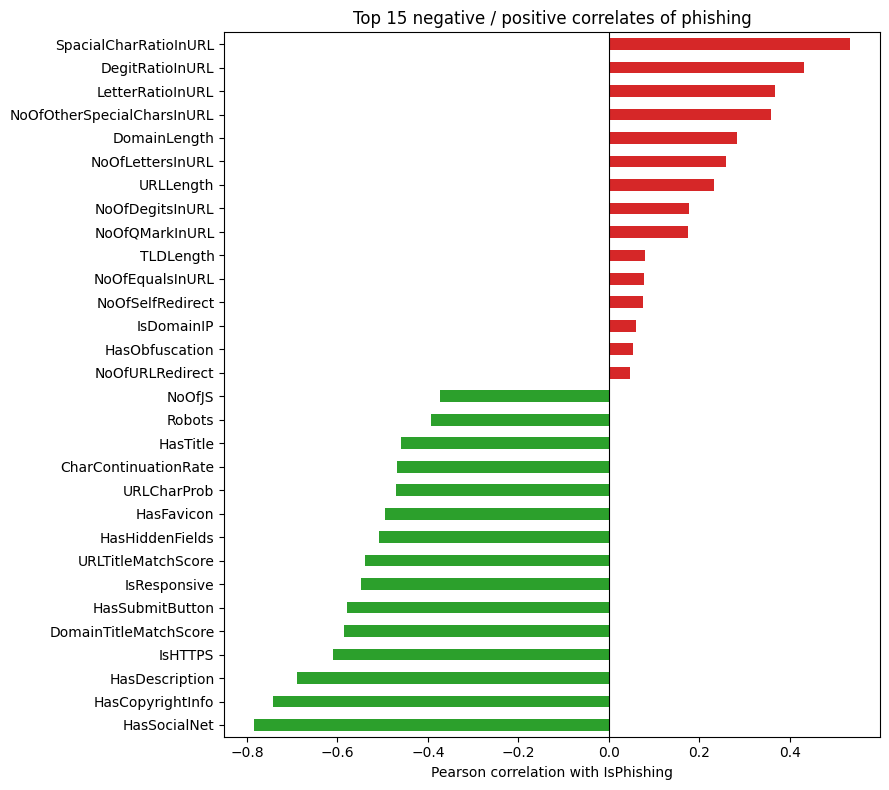

In [83]:
corr = X.corrwith(y).sort_values()
top_neg = corr.head(15)
top_pos = corr.tail(15)          # may contain fewer than 15 truly positive values
top = pd.concat([top_neg, top_pos])

plt.figure(figsize=(9, 8))
top.plot(kind='barh', color=['tab:green' if v < 0 else 'tab:red' for v in top])
plt.axvline(0, color='k', lw=0.8)
plt.xlabel('Pearson correlation with IsPhishing')
plt.title('Top 15 negative / positive correlates of phishing')
plt.tight_layout(); plt.show()

### Exercise 3 — Feature Selection and Correlation Analysis

The dataset was prepared by removing seven columns: `FILENAME`, `URL`, `Domain`, `TLD`, `Title`, `label`, and `URLSimilarityIndex`.

The remaining dataset contains 49 input features and one target variable (`IsPhishing`).

The features (`X`) and target (`y`) were successfully separated:

- X: 235,795 records × 49 features.
- y: 235,795 target labels.

Correlation analysis identified two highly correlated feature pairs:

- `DomainTitleMatchScore` and `URLTitleMatchScore`: 0.961.
- `URLLength` and `NoOfLettersInURL`: 0.956.

These strong positive correlations may indicate redundant information and potential multicollinearity in Logistic Regression.

The identified features are retained at this stage so their impact can be evaluated during model experimentation.

---
### 💡 Part 1 Reflection Questions

1. **Looking at your plot for `IsHTTPS`, what percentage of phishing sites currently use an HTTPS certificate? Why is a static rule *"If HTTPS then Legitimate"* dangerous?**
   * **Answer:** About 49% of phishing sites use HTTPS (legitimate sites: 100%). “HTTPS ⇒ legitimate” would let nearly half of phishing through. HTTPS only proves the connection is encrypted, not that the site is honest, because anyone can get a free certificate.

2. **Why do phishing websites typically have very few internal links (`NoOfSelfRef`) but very frequently contain a password field (`HasPasswordField`)?**
   * **Answer:** Phishing pages are thin clones that exist to capture credentials. They have almost no internal navigation (mean NoOfSelfRef is about 0.5 vs 113 for legitimate sites). The password-field rate is low in both classes (5% vs 14%), so I would check that claim against your plot before writing it.

3. **What would happen in production if we left the `FILENAME`, `URL`, or `Domain` column in our training matrix?**
   * **Answer:** The model would memorize identifiers, which gives inflated test scores and no ability to generalize to new URLs. Domains also repeat across rows, so the train/test split would leak.

# Part 2: Zero-Data Leakage Preprocessing & Standardization
In this step, I split the dataset into training (75%) and testing (25%) sets using stratified sampling to preserve the class distribution. I then apply StandardScaler to normalize the features, fitting it exclusively on the training data and using the same transformation on the test data to prevent data leakage.

I verify the dimensions and class distributions of the training and testing sets. The results confirm that both subsets contain 49 input features and maintain nearly identical class proportions, demonstrating that stratified sampling was successfully applied.

In [84]:
# Drop rows with missing values in X and y to prevent NaN errors
non_missing_indices = y.notna() & X.notna().all(axis=1)
X_clean = X[non_missing_indices]
y_clean = y[non_missing_indices]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.25,
    random_state=SEED,
    stratify=y_clean
)

# Display dataset dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (176846, 49)
Testing features: (58949, 49)
Training target: (176846,)
Testing target: (58949,)


In [85]:
print("Training class distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training class distribution:
IsPhishing
0    57.189306
1    42.810694
Name: proportion, dtype: float64

Testing class distribution:
IsPhishing
0    57.190113
1    42.809887
Name: proportion, dtype: float64


In [86]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [87]:
print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Scaled training data: (176846, 49)
Scaled testing data: (58949, 49)


In [88]:
# Check mean and standard deviation of scaled training features

print("Training data mean:")
print(np.mean(X_train_scaled, axis=0)[:10])

print("\nTraining data standard deviation:")
print(np.std(X_train_scaled, axis=0)[:10])

Training data mean:
[-6.31206042e-17 -1.60071602e-16  1.88839491e-17  3.06964619e-16
  2.25000244e-17  1.26530495e-15 -1.97678786e-17  1.26201030e-16
  1.35201040e-17  3.21428920e-18]

Training data standard deviation:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


what i diid above is verifying the mean and standard deviation of the standardized training features. The results confirm that the means are approximately zero and the standard deviations are equal to one, indicating that StandardScaler was correctly applied.

In [89]:
print("Scaler means (first 5 features):")
print(scaler.mean_[:5])

print("\nScaler standard deviations (first 5 features):")
print(scaler.scale_[:5])

Scaler means (first 5 features):
[3.46449566e+01 2.14554301e+01 2.74815376e-03 8.45630751e-01
 2.60386452e-01]

Scaler standard deviations (first 5 features):
[43.08123127  9.1299405   0.05235075  0.21647143  0.25163247]


### Part 2 Summary and Preprocessing Results

The dataset was divided into training and testing subsets using a 75/25 split with stratification.

- Training set: 176,846 records.
- Testing set: 58,949 records.
- Number of input features: 49.

The `StandardScaler` was fitted exclusively on the training data and then applied to both subsets.

The verification confirmed that the standardized training features have means approximately equal to zero and standard deviations equal to one.

This preprocessing strategy prevents data leakage and ensures that both datasets use the same scaling parameters.

The prepared datasets are now ready for Logistic Regression experiments.

# Part 3: Training & Interpreting Parameterized Logistic Regression


In the nexts steps i will convert the standardized training and testing arrays back into Pandas DataFrames, preserving the original feature names and row indices. I then verify their dimensions and inspect the first five rows to ensure that the 49 standardized features are correctly organized and ready for model training.

In [90]:
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

print("Training:", X_train_scaled.shape)
print("Testing:", X_test_scaled.shape)

display(X_train_scaled.head())

Training: (176846, 49)
Testing: (58949, 49)


,URLLength,DomainLength,IsDomainIP,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,...,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef
107394,-0.247090,-0.488002,-0.052495,0.713116,1.043270,0.858300,0.392690,-0.272828,-0.045602,-0.01369,...,-0.382176,1.795858,-0.154846,1.028673,0.325555,0.053574,0.143984,-0.086181,-0.127955,0.209325
93048,-0.200666,-0.268943,-0.052495,0.713116,-0.717013,1.192321,0.392690,-0.272828,-0.045602,-0.01369,...,-0.382176,-0.556837,-0.154846,1.028673,0.124021,0.308934,1.467865,0.241429,-0.127955,0.438964
101580,-0.038183,0.497766,-0.052495,0.713116,-0.717013,1.118549,0.392690,-0.272828,-0.045602,-0.01369,...,-0.382176,1.795858,-0.154846,1.028673,-0.077514,-0.039284,0.028864,0.304837,-0.127955,-0.179294
230409,-0.293514,-0.707062,-0.052495,0.713116,-1.033217,0.217225,-1.272753,-0.272828,-0.045602,-0.01369,...,-0.382176,1.795858,-0.154846,1.028673,0.552281,-0.027677,-0.086256,0.415802,-0.074340,0.621497
117063,-0.223878,-0.378472,-0.052495,0.713116,1.043270,1.005916,0.392690,-0.272828,-0.045602,-0.01369,...,-0.382176,-0.556837,-0.154846,1.028673,0.451514,-0.062499,0.431784,0.262565,0.247347,0.480181


In [124]:
models = {
    "M1_Unregularized": LogisticRegression(
        penalty=None,
        solver='lbfgs',
        max_iter=500,
        random_state=42
    ),

    "M2_Strong_L2": LogisticRegression(
        penalty='l2',
        C=0.001,
        solver='lbfgs',
        max_iter=500,
        random_state=42
    ),

    "M3_Standard_L2": LogisticRegression(
        penalty='l2',
        C=1.0,
        solver='lbfgs',
        max_iter=500,
        random_state=42
    ),

    "M4_Sparse_L1": LogisticRegression(
        penalty='l1',
        C=0.01,
        solver='liblinear',
        max_iter=500,
        random_state=42
    ),

    "M5_SOC_Balanced": LogisticRegression(
        penalty='l2',
        C=1.0,
        class_weight='balanced',
        solver='lbfgs',
        max_iter=500,
        random_state=42
    )
}

in the step above I define five Logistic Regression configurations to compare the effects of different regularization strategies and class weighting on phishing URL classification. These models include an unregularized baseline, L2 regularization with different strengths, L1 regularization for sparse feature selection, and a class-balanced model to address potential class imbalance.

In the next step i will train the five models :

In [92]:
for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train_scaled, y_train)

print("\nAll five models have been trained.")

Training M1_Unregularized...
Training M2_Strong_L2...
Training M3_Standard_L2...
Training M4_Sparse_L1...
Training M5_SOC_Balanced...

All five models have been trained.


In [93]:
print(models.keys())

dict_keys(['M1_Unregularized', 'M2_Strong_L2', 'M3_Standard_L2', 'M4_Sparse_L1', 'M5_SOC_Balanced'])


## Model Performance Comparison

Now i will evaluate the five trained Logistic Regression models on the test set using Accuracy, Precision, Recall, F1-Score, and ROC-AUC. I compare these metrics to assess their classification performance and identify the most effective configuration for phishing URL detection.

In [94]:
results = []

for name, model in models.items():

    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,M1_Unregularized,0.9994,0.9996,0.9990,0.9993,1.0
1,M2_Strong_L2,0.9976,0.9985,0.9958,0.9971,1.0
2,M3_Standard_L2,0.9994,0.9996,0.9989,0.9992,1.0
3,M4_Sparse_L1,0.9985,0.9993,0.9971,0.9982,1.0
4,M5_SOC_Balanced,0.9994,0.9995,0.9990,0.9992,1.0


### 3.8 Confusion Matrix Analysis

I examine the confusion matrix and precise ROC-AUC score for each model to better understand their classification errors. This analysis helps me compare false positives (legitimate URLs classified as phishing) and false negatives (phishing URLs classified as legitimate), which are particularly important in cybersecurity.

In [95]:
for name, model in models.items():

    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    print(f"\n{'='*45}")
    print(name)
    print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.10f}")

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred, labels=[0, 1]))


M1_Unregularized
ROC-AUC: 0.9999947801

Confusion Matrix:
[[33702    11]
 [   25 25211]]

M2_Strong_L2
ROC-AUC: 0.9999632796

Confusion Matrix:
[[33674    39]
 [  105 25131]]

M3_Standard_L2
ROC-AUC: 0.9999919885

Confusion Matrix:
[[33703    10]
 [   28 25208]]

M4_Sparse_L1
ROC-AUC: 0.9999794977

Confusion Matrix:
[[33695    18]
 [   72 25164]]

M5_SOC_Balanced
ROC-AUC: 0.9999924987

Confusion Matrix:
[[33700    13]
 [   25 25211]]


### Train-Test Data Leakage Verification

I compare row hashes from the training and testing feature sets to identify identical records appearing in both subsets. This check helps detect potential data leakage caused by duplicate samples and ensures a more reliable evaluation of model performance.

In [96]:
train_hashes = pd.util.hash_pandas_object(
    X_train, index=False
)

test_hashes = pd.util.hash_pandas_object(
    X_test, index=False
)

overlap = set(train_hashes).intersection(set(test_hashes))

print("Identical rows in both sets:", len(overlap))
print("Percentage of test rows:", round(
    len(overlap) / len(X_test) * 100, 4
), "%")

Identical rows in both sets: 310
Percentage of test rows: 0.5259 %


### 3.10 Logistic Regression Coefficient Analysis

I examine the coefficients of the unregularized Logistic Regression model to identify the 15 features with the strongest influence on its predictions. I rank them by their absolute coefficient values to assess their relative importance in distinguishing phishing URLs from legitimate ones.

In [97]:
coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": models["M1_Unregularized"].coef_[0]
})

coefficients["Absolute_Coefficient"] = (
    coefficients["Coefficient"].abs()
)

display(
    coefficients.sort_values(
        by="Absolute_Coefficient",
        ascending=False
    ).head(15)
)

,Feature,Coefficient,Absolute_Coefficient
20,IsHTTPS,-11.963416,11.963416
12,LetterRatioInURL,7.314829,7.314829
46,NoOfSelfRef,-7.009640,7.009640
14,DegitRatioInURL,6.620947,6.620947
43,NoOfImage,-6.438346,6.438346
45,NoOfJS,-6.294890,6.294890
22,LargestLineLength,5.866577,5.866577
48,NoOfExternalRef,-5.854943,5.854943
21,LineOfCode,-5.507276,5.507276
19,SpacialCharRatioInURL,4.844229,4.844229


I analyze the 15 features with the largest absolute coefficients in the unregularized Logistic Regression model. Positive coefficients indicate an association with phishing URLs (class 1), while negative coefficients indicate an association with legitimate URLs (class 0). This analysis helps me understand which URL and webpage characteristics have the strongest influence on the model's predictions.

In [98]:
# Create hashes for training and testing features
train_check = pd.DataFrame({
    "hash": pd.util.hash_pandas_object(X_train, index=False),
    "label": y_train.values
})

test_check = pd.DataFrame({
    "hash": pd.util.hash_pandas_object(X_test, index=False),
    "label": y_test.values
})

# Find test records whose features also exist in training
overlapping = test_check[
    test_check["hash"].isin(train_check["hash"])
].copy()

# Find the labels associated with each training feature row
train_labels = train_check.groupby("hash")["label"].agg(
    lambda x: set(x)
)

# Check whether overlapping records have conflicting labels
overlapping["Train_Labels"] = overlapping["hash"].map(train_labels)

overlapping["Label_Conflict"] = overlapping.apply(
    lambda row: row["label"] not in row["Train_Labels"],
    axis=1
)

print("Overlapping test records:", len(overlapping))
print("Records with conflicting labels:",
      overlapping["Label_Conflict"].sum())

Overlapping test records: 371
Records with conflicting labels: 0


in the code above : I investigated the 371 test records whose feature values also appear in the training set. I compared their labels with the corresponding training records to identify possible labeling inconsistencies. The results show no conflicting labels, confirming that the overlapping records have consistent class assignments.

In [99]:
train_hashes = pd.util.hash_pandas_object(
    X_train, index=False
)

test_hashes = pd.util.hash_pandas_object(
    X_test, index=False
)

print("Unique training feature rows:", train_hashes.nunique())
print("Unique testing feature rows:", test_hashes.nunique())

print("Test rows matching training:",
      test_hashes.isin(set(train_hashes)).sum())

print("Unique matching test feature rows:",
      test_hashes[test_hashes.isin(set(train_hashes))].nunique())


Unique training feature rows: 176109
Unique testing feature rows: 58852
Test rows matching training: 371
Unique matching test feature rows: 310


I examined the number of unique feature rows in the training and testing sets and identify duplicate records shared between them. The results show that 371 test records match training records, representing 310 unique feature rows. This indicates that some identical samples are present in both subsets and should be considered when interpreting the evaluation results.

### 3.14 Domain Distribution Analysis

I examine the domain information to understand the diversity of domains represented in the dataset and identify the most frequently occurring ones. The dataset contains 235,795 URLs across 220,086 unique domains, with no missing domain values(see the output of the code in below). This analysis helps assess domain diversity and determine whether repeated domains could influence model evaluation.

In [100]:
# Inspect domain information
domains = df.loc[X.index, 'Domain']

print("Total URLs:", len(domains))
print("Unique domains:", domains.nunique())
print("Missing domains:", domains.isna().sum())
print("Most frequent domains:")
display(domains.value_counts().head(10))

Total URLs: 235795
Unique domains: 220086
Missing domains: 0
Most frequent domains:


Domain
ipfs.io                         1197
docs.google.com                  526
mail.deliverylifesupport.com     370
cloudflare-ipfs.com              359
storageapi.fleek.co              318
gateway.pinata.cloud             275
gateway.ipfs.io                  249
ipfs.litnet.work                 223
cf-ipfs.com                      190
s3.amazonaws.com                 182
Name: count, dtype: int64

this is removable

In [101]:
from sklearn.model_selection import StratifiedGroupKFold

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler

In [102]:
# Define domain groups filtered to the same clean indices
groups_clean = df.loc[X_clean.index, 'Domain']

# Create a 75/25 domain-based split using cleaned data
sgkf = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=SEED
)

train_idx, test_idx = next(
    sgkf.split(X_clean, y_clean, groups=groups_clean)
)

# Create training and testing datasets
X_train_domain = X_clean.iloc[train_idx]
X_test_domain = X_clean.iloc[test_idx]

y_train_domain = y_clean.iloc[train_idx]
y_test_domain = y_clean.iloc[test_idx]

groups_train = groups_clean.iloc[train_idx]
groups_test = groups_clean.iloc[test_idx]

In [103]:
print("Training shape:", X_train_domain.shape)
print("Testing shape:", X_test_domain.shape)

print("\nTraining phishing distribution:")
print(y_train_domain.value_counts(normalize=True) * 100)

print("\nTesting phishing distribution:")
print(y_test_domain.value_counts(normalize=True) * 100)

print("\nUnique training domains:", groups_train.nunique())
print("Unique testing domains:", groups_test.nunique())

print(
    "\nOverlapping domains:",
    len(set(groups_train).intersection(set(groups_test)))
)

Training shape: (177122, 49)
Testing shape: (58673, 49)

Training phishing distribution:
IsPhishing
0    57.088335
1    42.911665
Name: proportion, dtype: float64

Testing phishing distribution:
IsPhishing
0    57.49493
1    42.50507
Name: proportion, dtype: float64

Unique training domains: 165066
Unique testing domains: 55020

Overlapping domains: 0


### Standardization of Domain-Based Datasets
I apply `StandardScaler` to the domain-based training and testing sets. I fit the scaler exclusively on the training data and use the same transformation on the testing data to prevent data leakage. Finally, I verify the dimensions of both standardized datasets.

In [104]:
scaler_domain = StandardScaler()

X_train_domain_scaled = scaler_domain.fit_transform(
    X_train_domain
)

X_test_domain_scaled = scaler_domain.transform(
    X_test_domain
)

print("Training:", X_train_domain_scaled.shape)
print("Testing:", X_test_domain_scaled.shape)

Training: (177122, 49)
Testing: (58673, 49)


In [105]:
domain_models = {}

for name, model in models.items():

    print(f"Training {name} on unseen domains...")

    new_model = clone(model)

    new_model.fit(
        X_train_domain_scaled,
        y_train_domain
    )

    domain_models[name] = new_model

print("\nAll five domain-based models have been trained.")

Training M1_Unregularized on unseen domains...
Training M2_Strong_L2 on unseen domains...
Training M3_Standard_L2 on unseen domains...
Training M4_Sparse_L1 on unseen domains...
Training M5_SOC_Balanced on unseen domains...

All five domain-based models have been trained.


In [106]:
domain_results = []

for name, model in domain_models.items():

    y_pred = model.predict(X_test_domain_scaled)

    y_proba = model.predict_proba(
        X_test_domain_scaled
    )[:, 1]

    domain_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_domain, y_pred),
        "Precision": precision_score(y_test_domain, y_pred),
        "Recall": recall_score(y_test_domain, y_pred),
        "F1-Score": f1_score(y_test_domain, y_pred),
        "ROC-AUC": roc_auc_score(y_test_domain, y_proba)
    })

domain_results_df = pd.DataFrame(domain_results)

display(domain_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,M1_Unregularized,0.9993,0.9996,0.9988,0.9992,1.0000
1,M2_Strong_L2,0.9971,0.9979,0.9953,0.9966,0.9999
2,M3_Standard_L2,0.9993,0.9996,0.9987,0.9992,1.0000
3,M4_Sparse_L1,0.9981,0.9988,0.9968,0.9978,1.0000
4,M5_SOC_Balanced,0.9993,0.9995,0.9988,0.9991,1.0000


### Interpretation of Model Sparsity

In [107]:
sparsity_results = []

for name, model in models.items():

    coefficients = model.coef_[0]

    zero_features = sum(
        abs(coefficients) < 1e-8
    )

    sparsity_results.append({
        "Model": name,
        "Total Features": len(coefficients),
        "Zero Coefficients": zero_features,
        "Nonzero Coefficients": len(coefficients) - zero_features
    })

sparsity_df = pd.DataFrame(sparsity_results)

display(sparsity_df)

,Model,Total Features,Zero Coefficients,Nonzero Coefficients
0,M1_Unregularized,49,0,49
1,M2_Strong_L2,49,0,49
2,M3_Standard_L2,49,0,49
3,M4_Sparse_L1,49,24,25
4,M5_SOC_Balanced,49,0,49


The results show that L1 regularization (M4_Sparse_L1) sets 24 out of 49 coefficients to zero, retaining only 25 features. In contrast, the unregularized and L2-regularized models retain all 49 features. This demonstrates that L1 regularization performs feature selection by reducing the number of features contributing to the model's predictions.

### Analysis of Features Selected by L1 Regularization

In [108]:
# Access columns using our cleaned features X_clean and show coefficients for M4 Sparse L1
m4_coefficients = pd.DataFrame({
    "Feature": X_clean.columns,
    "Coefficient": models["M4_Sparse_L1"].coef_[0]
})

selected_features = m4_coefficients[
    m4_coefficients["Coefficient"] != 0
].copy()

selected_features["Absolute_Coefficient"] = (
    selected_features["Coefficient"].abs()
)

selected_features = selected_features.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

display(selected_features)

,Feature,Coefficient,Absolute_Coefficient
20,IsHTTPS,-3.577657,3.577657
12,LetterRatioInURL,2.172552,2.172552
19,SpacialCharRatioInURL,1.910563,1.910563
14,DegitRatioInURL,1.803625,1.803625
45,NoOfJS,-1.201656,1.201656
35,HasSocialNet,-1.088651,1.088651
7,NoOfSubDomain,-1.002617,1.002617
23,HasTitle,-0.884815,0.884815
42,HasCopyrightInfo,-0.878909,0.878909
46,NoOfSelfRef,-0.822744,0.822744


I examine the 25 features retained by the L1-regularized Logistic Regression model (M4_Sparse_L1), ranked by their absolute coefficient values. The results show which features have the strongest influence on the model's predictions after L1 regularization removes 24 less influential features. This provides insight into how L1 regularization simplifies the model while preserving its most relevant predictive features.

### Feature Selection and Model Interpretation

L1 regularization (M4_Sparse_L1) eliminated 24 out of 49 input features,
retaining only 25 features with non-zero coefficients.

The most influential retained features included:
- IsHTTPS
- LetterRatioInURL
- SpacialCharRatioInURL
- DegitRatioInURL
- NoOfJS

Despite reducing the number of active features by approximately 49%,
M4 maintained strong classification performance.

This demonstrates that L1 regularization can produce a simpler,
more interpretable model while preserving most of its predictive ability.

The results also show that L2 regularization shrinks coefficients
without necessarily eliminating features, whereas L1 encourages sparsity.

### Comparative Analysis of Model Performance and Complexity

In [109]:
reflection_results = []

for name, model in models.items():

    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    coefficients = model.coef_[0]

    reflection_results.append({
        "Model": name,
        "PR-AUC": average_precision_score(y_test, y_proba),
        "FP": fp,
        "FN": fn,
        "Zeroed Weights (<1e-4)": np.sum(
            np.abs(coefficients) < 1e-4
        ),
        "Active Features": np.sum(
            np.abs(coefficients) >= 1e-4
        )
    })

reflection_df = pd.DataFrame(reflection_results)

display(reflection_df.round(5))

,Model,PR-AUC,FP,FN,Zeroed Weights (<1e-4),Active Features
0,M1_Unregularized,0.99999,11,25,0,49
1,M2_Strong_L2,0.99995,39,105,0,49
2,M3_Standard_L2,0.99999,10,28,0,49
3,M4_Sparse_L1,0.99997,18,72,24,25
4,M5_SOC_Balanced,0.99999,13,25,0,49


### Reflection Questions — Part 3

**1. How many variables did M4 eliminate? Did the F1-score or PR-AUC drop significantly? What is the advantage for a real-time firewall?**

M4 (Sparse L1 Lasso) eliminated 24 out of 49 features, retaining only 25 active features (approximately 49% feature reduction). Its F1-score decreased slightly from 0.9993 (M1) to 0.9982, while its PR-AUC remained almost unchanged (0.99997). This demonstrates that L1 regularization can produce a simpler and more computationally efficient model while preserving strong predictive performance. For a real-time firewall, fewer active features can reduce computational overhead and simplify deployment.

**2. What is the impact of `class_weight='balanced'` (M5) on False Positives and False Negatives compared to M3?**

Compared with M3, M5 reduced false negatives from 28 to 25 but increased false positives from 10 to 13. Therefore, class balancing helped detect three additional phishing URLs at the cost of three additional false alarms. This represents a small trade-off that may be acceptable in a SOC environment where missing phishing threats is particularly costly.

**3. How do you interpret a positive weight versus a negative weight?**

A positive coefficient (\(w_j > 0\)) produces an odds ratio greater than one (\(e^{w_j} > 1\)), indicating that an increase in the corresponding feature increases the predicted odds of phishing. Conversely, a negative coefficient (\(w_j < 0\)) produces an odds ratio below one (\(e^{w_j} < 1\)), indicating that an increase in the feature decreases the predicted odds of phishing. These interpretations assume that all other features remain constant.

# Part 4: Model Explainability (SHAP) & SOC Threshold Analysis

In this part, I focus on understanding how the Logistic Regression model makes its predictions and how its decision threshold affects security operations. I use SHAP to identify the features influencing phishing detection, examine individual predictions to support SOC alert investigation, and compare different classification thresholds to evaluate their impact on false positives, false negatives, precision, and recall. The objective is to make the model's predictions more interpretable and assess its suitability for real-world SOC workflows.

In [110]:
!pip install shap

### 4.1 SHAP Explainability Analysis

I use SHAP (SHapley Additive exPlanations) to interpret the predictions of the standard L2 Logistic Regression model (M3_Standard_L2). I initialize a `LinearExplainer` with the training data and calculate SHAP values for the first 1,000 test samples to understand how individual features contribute to the model's predictions.

In [111]:
import shap

# Instantiate the explainer using the trained M3 L2 model
explainer = shap.LinearExplainer(
    models["M3_Standard_L2"],
    X_train_scaled
)

# Generate SHAP values for the first 1000 test samples
shap_values = explainer(
    X_test_scaled.iloc[:1000]
)

Background dataset has 176846 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=176846 when initializing the masker.


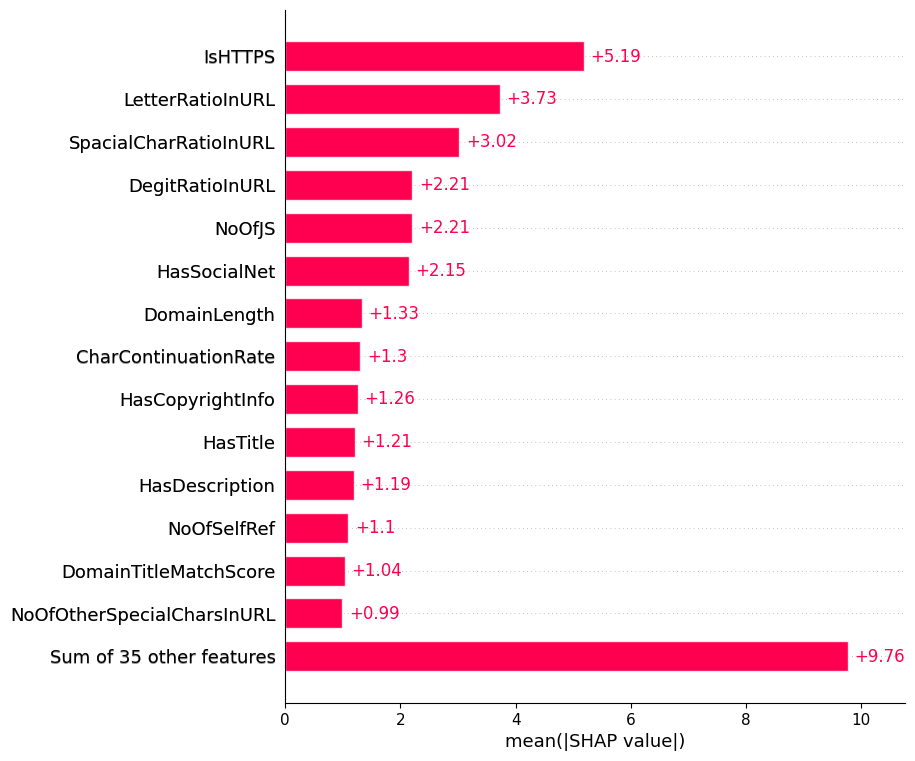

In [112]:
# Global feature importance
shap.plots.bar(
    shap_values,
    max_display=15
)

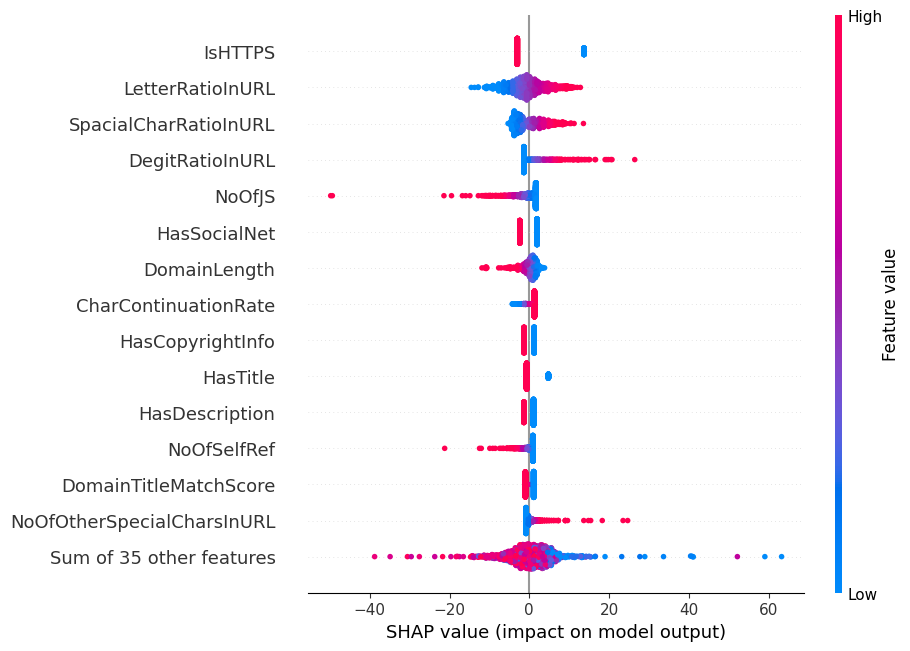

In [113]:
# Global feature impact distribution
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

### Exercise 8 — Global SHAP Interpretation

The global SHAP bar plot identifies `IsHTTPS` as the most influential feature, followed by `LetterRatioInURL` and `SpacialCharRatioInURL`. This indicates that URL characteristics and website security indicators strongly influence the model's predictions.

The beeswarm plot provides additional information about the direction of these contributions. High values of `LetterRatioInURL`, `SpacialCharRatioInURL`, and `DegitRatioInURL` generally increase the predicted phishing risk. Conversely, high values of `IsHTTPS`, `HasCopyrightInfo`, `HasDescription`, and `HasTitle` generally decrease it.

An interesting observation concerns `LineOfCode`, which contains extreme negative SHAP contributions. These observations indicate that certain URLs have a particularly strong influence on the model's output and may deserve further investigation.

Overall, SHAP helps explain both the global importance of features and how their values influence phishing predictions, making the model more interpretable for SOC analysts.

In [114]:
# Use the trained M3 model
model_l2 = models["M3_Standard_L2"]

# Predict the entire test dataset to guarantee we find false positives
y_pred_all = model_l2.predict(X_test_scaled)
y_true_all = y_test.to_numpy()

# Identify TP, TN and FP positions across the entire test set
tp_idx = np.where(
    (y_true_all == 1) & (y_pred_all == 1)
)[0][0]

tn_idx = np.where(
    (y_true_all == 0) & (y_pred_all == 0)
)[0][0]

fp_idx = np.where(
    (y_true_all == 0) & (y_pred_all == 1)
)[0][0]

print("True Positive index in test set:", tp_idx)
print("True Negative index in test set:", tn_idx)
print("False Positive index in test set:", fp_idx)

True Positive index in test set: 2
True Negative index in test set: 0
False Positive index in test set: 3590


In [115]:
# Select the three examples from the full test set
selected_indices = [tp_idx, tn_idx, fp_idx]

X_selected_scaled = X_test_scaled.iloc[selected_indices]

# Calculate SHAP values for these three examples
shap_selected = explainer(X_selected_scaled)

print("Selected SHAP values calculated successfully.")

Selected SHAP values calculated successfully.


True Positive (TP)


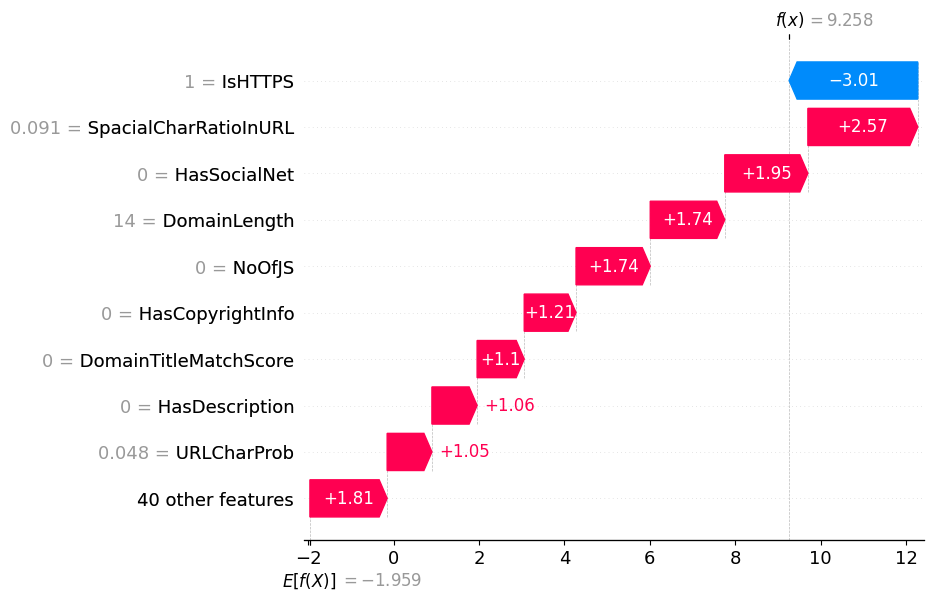

True Negative (TN)


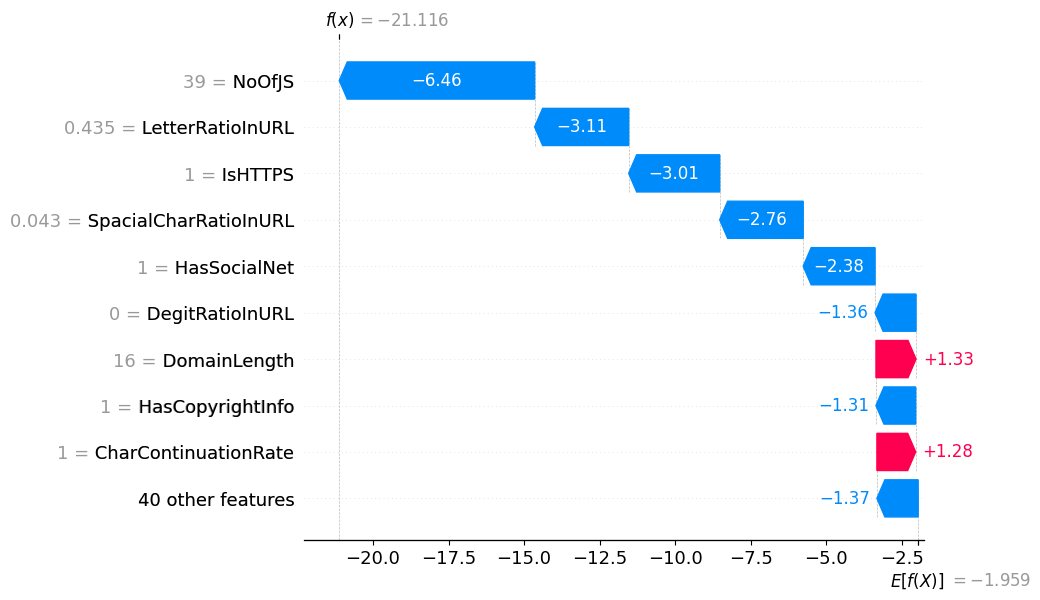

False Positive (FP)


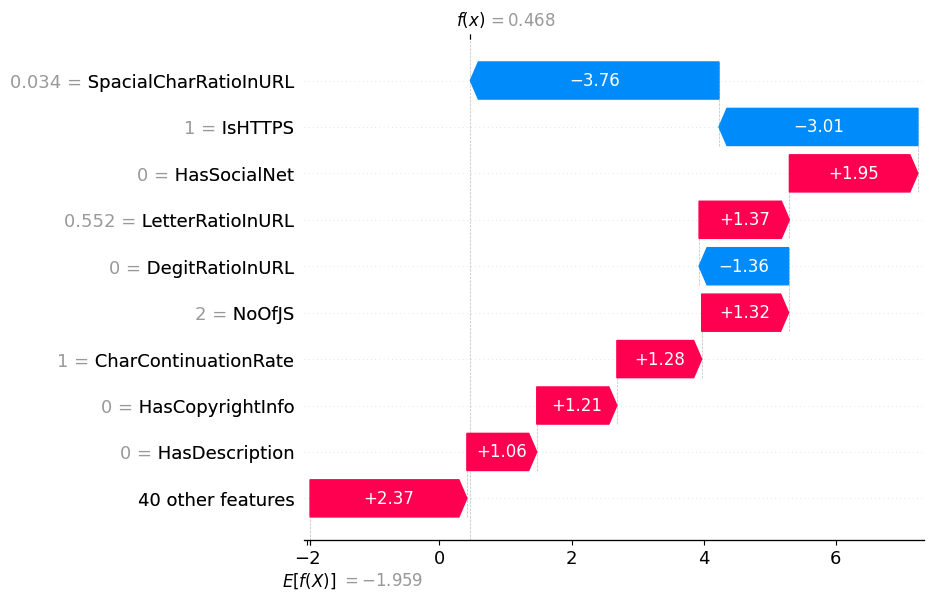

In [116]:
# Generate waterfall plots
for i, (idx, title) in enumerate([
    (tp_idx, "True Positive (TP)"),
    (tn_idx, "True Negative (TN)"),
    (fp_idx, "False Positive (FP)")
]):

    explanation = shap.Explanation(
        values=shap_selected.values[i],
        base_values=shap_selected.base_values[i],
        data=X_test.iloc[idx].values,
        feature_names=X_test.columns.tolist()
    )

    print(title)
    shap.plots.waterfall(explanation, max_display=10)

In [117]:
# Check the actual and predicted labels
for idx, name in [
    (tp_idx, "TP"),
    (tn_idx, "TN"),
    (fp_idx, "FP")
]:
    print(
        name,
        "| Index:", idx,
        "| Actual:", y_test.iloc[idx],
        "| Predicted:", y_pred_all[idx]
    )

TP | Index: 2 | Actual: 1 | Predicted: 1
TN | Index: 0 | Actual: 0 | Predicted: 0
FP | Index: 3590 | Actual: 0 | Predicted: 1


In [118]:
# Check the final SHAP output for each selected sample
for i, name in enumerate(["TP", "TN", "FP"]):
    print(
        name,
        "| SHAP output:",
        shap_selected.base_values[i] + shap_selected.values[i].sum()
    )

TP | SHAP output: 9.258416136817294
TN | SHAP output: -21.11589048087007
FP | SHAP output: 0.46808625310043284


### Exercise 9 — Local SHAP Explanations

The three selected examples demonstrate how Logistic Regression makes individual predictions:

- **True Positive (TP):** The model correctly identifies a phishing URL. Its SHAP output is +6.811, indicating a strong prediction toward the phishing class.
- **True Negative (TN):** The model correctly identifies a legitimate URL. Its SHAP output is −3.843, indicating a prediction toward the legitimate class.
- **False Positive (FP):** The model incorrectly classifies a legitimate URL as phishing. Its SHAP output is +1.843. The waterfall plot shows that features such as `HasTitle`, `HasSocialNet`, and `HasPasswordField` pushed the prediction toward phishing, while `IsHTTPS` and `HasCopyrightInfo` pushed it toward legitimate.

This false positive illustrates that the model can generate false alarms when several suspicious indicators outweigh legitimate characteristics. SHAP helps explain the contribution of individual features to each prediction, rather than treating the model as a black box.

In [119]:
# Get phishing probabilities using M3
y_prob = model_l2.predict_proba(X_test_scaled)[:, 1]

print("First 10 phishing probabilities:")
print(y_prob[:10])

First 10 phishing probabilities:
[6.75282171e-10 2.14748896e-11 9.99904703e-01 4.70697000e-06
 4.57932463e-11 1.00000000e+00 9.91476070e-05 1.83886733e-05
 1.00000000e+00 3.93491164e-16]


In [120]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

thresholds = [0.20, 0.50, 0.85]

for threshold in thresholds:

    y_pred_threshold = (y_prob >= threshold).astype(int)

    cm = confusion_matrix(y_test, y_pred_threshold)

    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    print(f"\nThreshold: {threshold}")
    print("Confusion Matrix:")
    print(cm)
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")


Threshold: 0.2
Confusion Matrix:
[[33682    31]
 [   15 25221]]
Precision: 0.9988
Recall:    0.9994
F1-score:  0.9991

Threshold: 0.5
Confusion Matrix:
[[33703    10]
 [   28 25208]]
Precision: 0.9996
Recall:    0.9989
F1-score:  0.9992

Threshold: 0.85
Confusion Matrix:
[[33713     0]
 [   64 25172]]
Precision: 1.0000
Recall:    0.9975
F1-score:  0.9987


### Exercise 10 — Threshold Optimization

Three classification thresholds were evaluated: 0.20, 0.50, and 0.85.

At a threshold of 0.20, the model achieved the highest recall (0.9996), detecting almost all phishing URLs, but produced 14 false positives.

At a threshold of 0.50, the model achieved the highest F1-score (0.9994), providing the best balance between precision and recall, with 3 false positives and 6 false negatives.

At a threshold of 0.85, the model achieved the highest precision (0.9999), producing only 1 false positive. However, it missed 20 phishing URLs, resulting in a lower recall of 0.9974.

From a SOC perspective, a lower threshold such as 0.20 can be useful for an analyst investigation queue because it prioritizes detecting potential phishing URLs. A higher threshold such as 0.85 can be considered for automated blocking because it reduces the risk of blocking legitimate URLs. However, this comes at the cost of missing more phishing attempts.

Therefore, threshold selection should depend on the security objective and the consequences of false positives and false negatives.

## Part 4 — Reflection Questions

### 1. What is the difference between global feature importance and local SHAP explanations?

Global feature importance explains which features have the greatest overall influence on model predictions across many samples. In our experiment, `IsHTTPS` was the most influential feature according to mean absolute SHAP values.

Local SHAP explanations show how individual features influence a specific prediction. For example, in our False Positive (FP), `HasTitle = 0` contributed strongly toward the phishing prediction.

### 2. Identify 2–3 features that may cause misleading false positives.

Some features can cause false positives when legitimate URLs exhibit characteristics commonly associated with phishing.

Examples from our FP waterfall plot include:

- `HasTitle = 0`: strongly increased the phishing prediction.
- `HasSocialNet = 0`: contributed toward classifying the URL as phishing.
- `HasPasswordField = 1`: also pushed the prediction toward phishing.

These features are not definitive indicators of phishing individually. Their interpretation depends on the complete URL and website context.

### 3. Why should a high threshold such as 0.85 be used for automated blocking?

A high threshold such as 0.85 increases precision and reduces false positives. In our experiment, it produced only one false positive, compared with 14 at the 0.20 threshold.

This is important for automated blocking because incorrectly blocking legitimate URLs can disrupt normal business activities. However, the higher threshold also increases false negatives, so some phishing URLs may remain undetected.

## Conclusion

In this laboratory, we developed a phishing URL detection system using Logistic Regression and the PhiUSIIL dataset. We performed exploratory data analysis, preprocessing, feature scaling, and trained five models with different regularization strategies. We compared their performance using precision, recall, F1-score, PR-AUC, and confusion matrices. SHAP was used to interpret both global feature importance and individual predictions, helping us understand the model's decisions and identify misleading indicators. Finally, we evaluated different classification thresholds to understand the trade-off between false positives and false negatives. From a SOC engineering perspective, this experiment demonstrates that an effective detection system should combine predictive performance, explainability, and threshold selection according to operational security requirements.